# Numerical Solution to ODEs: Leapfrog Method for an IVP problem

## Problem statement:
We aim to implement the **leapfrog method** to solve the Initial Value Problem (IVP) for an Ordinary Differential Equation (ODE). We are trying to solve an IVP that describes an electron plasma oscillation.

The governing equations are: \
$\frac{dx}{dt} = v$,  $\frac{dv}{dt} = -\omega^2_p x$, \
where $x$ is the position of the electron particle, $v$ is its velocity, and $\omega_p$ is the plasma frequency.

The initial conditions are: \
$x(t) = 0.5cost$, $v(t)= -0.5sint$.\
We will initialise x and v at each time step and solve the problem.

## Approach and numerical method:

The leapfrog method stores position and velocity at different time intervals: 
 - Position $x_n$ is stored at the full time interval $t_n = nh$.
 - Velocity $V_{n+1/2}$ is stored at the half time interval $ t_{n+1/2} h$.
 - $h$ is the time-step size.

For this problem, the acceleration is $a(x) = -x$, as $\omega_p = 1$. And the velocity and position are then given by: \
$v_{n+1/2} = v_{n-1/2} -hx_n$ \
$x_{n+1} = x_n + hv_{n+1/2}$. 

The half-time velocity is initialised using: \
$v_{-1/2} = v_0 - \frac{h}{2} a(x_0)$. \
Since $a(x_0) = -x_0 = -0.5$, the initial half - time velocity is $v_{-1/2} = \frac{h}{4}$. For $h = 0.1$, this gives $v_{-1/2} = 0.025$.

The same operations can be applied to Numpy arrays, so the function can update several particles at once.

## Numerical algorithm
The algorithm is: 
1. Set $x_0 = 0.5, v_0 = 0$, choose $h$, and calculate the initial half-time velocity.
2. At each step, update the velocity using the acceleration at the current position.
3. Update the position using the new half-time velocity.
4. Store the numerical values and compare them with the exact solution.

The function below performs one kick-drift step. The velocity provided to it is the velocity at the previous half-time.

In [1]:
# do not change line below
#from google.colab import files

import numpy as np
import matplotlib.pyplot as plt

In [2]:
#defining the function
def leapfrog(x, v, h):
    a = -x #acceleration at the current position
    v_new = v+h*a #kick update the velocity
    x_new = x+h*v_new #drift update the position

    return x_new, v_new

#test run
x_test, v_test = leapfrog(0.5, 0.025, 0.1)
print("Scalar test:", "x_new = ", x_test,"v_new = ", v_test)

x_array = np.array([0.5, 1.0, 1.5])
v_array = np.array([0.025, 0.05, 0.075])
x_array_new, v_array_new = leapfrog(x_array, v_array, 0.1)
print("Array test: x_new = ", x_array)

Scalar test: x_new =  0.4975 v_new =  -0.025
Array test: x_new =  [0.5 1.  1.5]


## Results and Discussion

### Numerical solution for $h=0.1$
We shall set $h=0.1$ and obtain the solution with time steps from $t=0$ to $t=20$. Position is plotted at all time levels and velocity at half-time levels. The time coordinates used for the velocity are thus shifted by half a time step. 

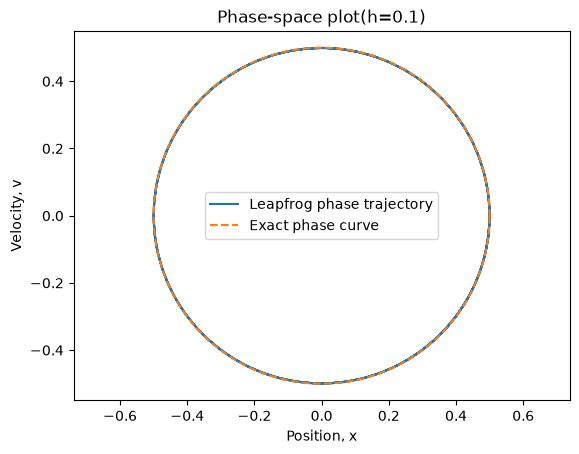

In [8]:
h= 0.1
t_final = 20.0
N = int(round(t_final/h))

x=0.5
v0=0.0
v_half = v0-(h/2)*(-x)

t_x = np.arange(N+1)*h
t_v = (np.arange(N+1)-0.5)*h

x_values = np.zeros(N+1)
v_half_values = np.zeros(N+1)
x_values[0]=x
v_half_values[0]=v_half

for n in range(N):
    x,v_half = leapfrog(x, v_half, h)
    x_values[n+1] = x
    v_half_values[n+1] = v_half

x_exact = 0.5*np.cos(t_x)
v_exact= -0.5*np.sin(t_v)

v_whole = 0.5*(v_half_values[:-1]+v_half_values[1:])
plt.figure()
plt.plot(x_values[:-1], v_whole, label="Leapfrog phase trajectory")
theta= np.linspace(0,2*np.pi,400)
plt.plot(0.5*np.cos(theta), -0.5*np.sin(theta), '--', label="Exact phase curve")
plt.xlabel("Position, x")
plt.ylabel("Velocity, v")
plt.title("Phase-space plot(h=0.1)")
plt.axis("equal")
plt.legend()
plt.show()



### Error and convergence study
The maximum position error over the interval is calculated for each time step: \
$e(h) = \max_n \left|x_n - x(t_n)\right|$.

The observed order of convergence is calculated using: \
$p = \log_2\left(\frac{e(h)}{e(h/2)}\right)$.

First, the method is tested with the half-step velocity initialised using the formula described above. It is then tested with the unstaggered initial condition,
$v_{-1/2} = v_0$. \
The error table and convergence plot are generated using the following code cell. With the correct half-step initialisation, the method is expected to show approximately second-order convergence. The unstaggered initialisation generally reduces the observed order of convergence. The unstaggered initialisation generally reduces the observed order of convergence because it introduces an initialisation error of order $(h)$. As a result, the overall solution generally exhibits first-order convergence instead of second-order convergence.

Correctly staggered initialisation
         h      maximum error     observed order
    0.2000     5.71629331e-01                  —
    0.1000     5.50593807e-01             0.0541
    0.0500     5.45748772e-01             0.0128
    0.0250     5.44448541e-01             0.0034

Unstaggered initialisation: v(-h/2) = v(0)
         h      maximum error     observed order
    0.2000     6.13196697e-01                  —
    0.1000     5.71976751e-01             0.1004
    0.0500     5.56178648e-01             0.0404
    0.0250     5.49672968e-01             0.0170


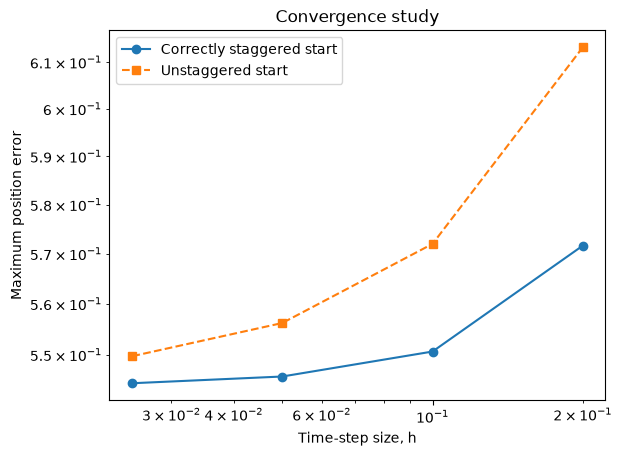

In [3]:
def solve_position(h, staggered=True):
    t_final = 20.0
    N= int(round(t_final/h))
    x=0.5
    v0=0.0

    if staggered:
        v_half=v0-(h/2)*(-x)
    else:
        v_half=v0
    x_values = np.zeros(N+1)
    x_values[0]=x

    for n in range(N):
        x, v_half=leapfrog(x, v_half, h)
        x_values[n+1]=x

    t= np.zeros(N+1)
    x_values[0]=x

    for n in range(N):
        x, v_half=leapfrog(x, v_half, h)
        x_values[n+1] = x

    t= np.arange(N+1)*h
    return t, x_values

h_values = [0.2, 0.1, 0.05, 0.025]

def convergence_table(staggered):
    errors=[]
    for step in h_values:
        t, x_num = solve_position(step, staggered=staggered)
        x_true=0.5*np.cos(t)
        errors.append(np.max(np.abs(x_num - x_true)))

    orders=[np.nan]
    for i in range(1, len(errors)):
        orders.append(np.log2(errors[i-1]/errors[i]))

    return errors, orders

errors_staggered, orders_staggered = convergence_table(staggered=True)
errors_unstaggered, orders_unstaggered = convergence_table(staggered=False)

print("Correctly staggered initialisation")
print(f"{'h':>10} {'maximum error':>18} {'observed order':>18}")
for h_i, err, order in zip(h_values, errors_staggered, orders_staggered):
    order_text = "—" if np.isnan(order) else f"{order:.4f}"
    print(f"{h_i:10.4f} {err:18.8e} {order_text:>18}")

print("\nUnstaggered initialisation: v(-h/2) = v(0)")
print(f"{'h':>10} {'maximum error':>18} {'observed order':>18}")
for h_i, err, order in zip(h_values, errors_unstaggered, orders_unstaggered):
    order_text = "—" if np.isnan(order) else f"{order:.4f}"
    print(f"{h_i:10.4f} {err:18.8e} {order_text:>18}")

plt.figure()
plt.loglog(h_values, errors_staggered, "o-", label="Correctly staggered start")
plt.loglog(h_values, errors_unstaggered, "s--", label="Unstaggered start")
plt.xlabel("Time-step size, h")
plt.ylabel("Maximum position error")
plt.title("Convergence study")
plt.legend()
plt.show()

### Order of Method: solving IVP using position variable only

The leapfrog method consists of a drift step and a kick step. From the drift equation, \
$x_{n+1}=x_n+h v_{n+1/2}$,

the velocity at the half-time levels can be expressed in terms of position as
$v_{n+1/2}=\frac{x_{n+1}-x_n}{h}, \qquad v_{n-1/2}=\frac{x_n-x_{n-1}}{h}$. 

Substituting these expressions into the kick equation, \
$v_{n+1/2}=v_{n-1/2}-h\omega_p^2x_n$, \
gives: \
$ \frac{x_{n+1}-x_n}{h} = \frac{x_n-x_{n-1}}{h}-h\omega_p^2x_n$. 

Multiplying both sides by $h$ and rearranging, we obtain \
$\boxed{x_{n+1}-2x_n+x_{n-1} =-\omega_p^2h^2x_n}$

Equivalently, the recurrence relation can be written as: \
$\boxed{x_{n+1}=(2-\omega_p^2h^2)x_n-x_{n-1}}$ \
This is a central-difference equation for position because it relates the positions at three consecutive time levels. The equation allows the position to be calculated without explicitly updating the velocity at every step.\ 

To verify the derived equation, the position values obtained using this recurrence relation are compared with those obtained using the leapfrog method. The two solutions should agree up to numerical round-off error when the same initial conditions are used.

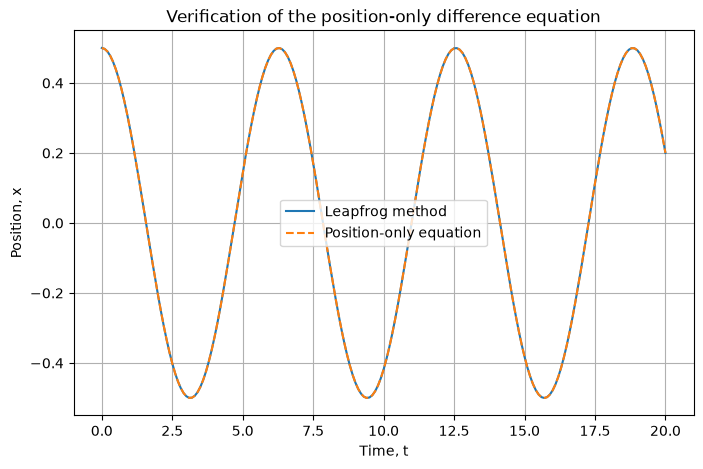

Maximum difference between the two solutions: 1.332268e-15


In [4]:
omega_p = 1.0
h = 0.1
t_final = 20.0
N = int(round(t_final / h))

x0 = 0.5
v0 = 0.0

#Solve using the leapfrog method
x = x0
v_half = v0 - (h / 2) * (-omega_p**2 * x0)

x_leapfrog = np.zeros(N + 1)
x_leapfrog[0] = x0

for n in range(N):
    x, v_half = leapfrog(x, v_half, h)
    x_leapfrog[n + 1] = x

#Solve using the position-only recurrence relation
x_difference = np.zeros(N + 1)
x_difference[0] = x0

#Obtain x_1 from the first leapfrog step
x_difference[1] = x0 + h * (v0 - (h / 2) * (-omega_p**2 * x0) - h * omega_p**2 * x0)

for n in range(1, N):
    x_difference[n + 1] = ((2 - omega_p**2 * h**2) * x_difference[n]- x_difference[n - 1])

#Compare both methods
t = np.arange(N + 1) * h

plt.figure(figsize=(8, 5))
plt.plot(t, x_leapfrog, label="Leapfrog method")
plt.plot(t, x_difference, "--", label="Position-only equation")
plt.xlabel("Time, t")
plt.ylabel("Position, x")
plt.title("Verification of the position-only difference equation")
plt.legend()
plt.grid(True)
plt.show()

#Calculate the maximum difference between the solutions
max_difference = np.max(np.abs(x_leapfrog - x_difference))
print("Maximum difference between the two solutions:", f"{max_difference:.6e}")